[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/notebooks/04_overfitting_regularization.ipynb)

<div dir="rtl">

# جلسه ۴: رگرسیون چندجمله‌ای، بیش‌برازش و منظم‌سازی

**اهداف این جلسه**

- مدل‌سازی رابطه‌های غیرخطی با رگرسیون چندجمله‌ای
- درک عمیق **بیش‌برازش (Overfitting)** و **کم‌برازش (Underfitting)**
- آشنایی با **مصالحه‌ی بایاس و واریانس (Bias–Variance Tradeoff)**
- رسم و تفسیر منحنی اعتبارسنجی و منحنی یادگیری
- منظم‌سازی (Regularization) با **Ridge**، **Lasso** و **Elastic Net**
- انتخاب ضریب منظم‌سازی با اعتبارسنجی متقابل

</div>

<div dir="rtl">

## ۱. وقتی رابطه خطی نیست

داده‌ای می‌سازیم که رابطه‌ی واقعی آن درجه‌ی دوم است: $y = 0.5x^2 + x + 2 + \text{noise}$.

</div>

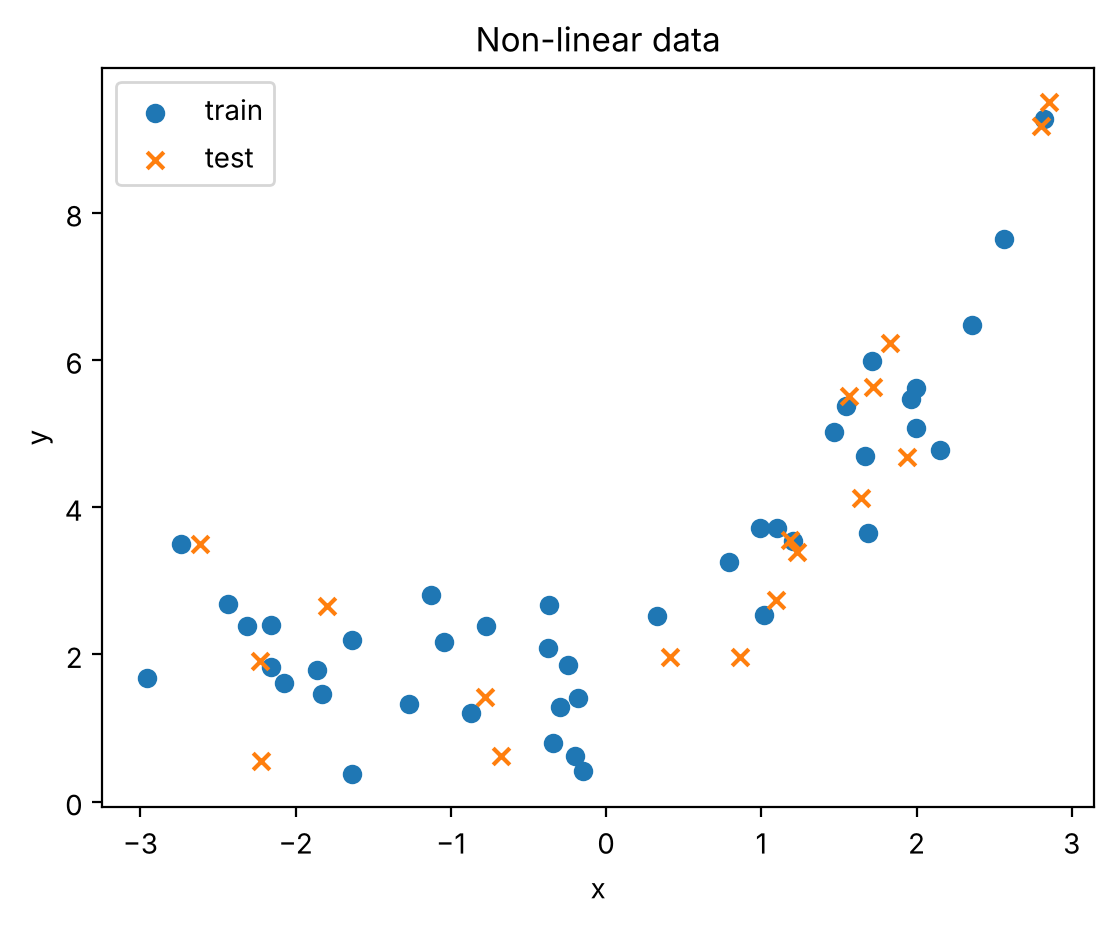

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)
m = 60
X = 6 * rng.random((m, 1)) - 3
y = 0.5 * X[:, 0] ** 2 + X[:, 0] + 2 + rng.normal(0, 1, m)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

plt.scatter(X_train, y_train, label="train")
plt.scatter(X_test, y_test, label="test", marker="x")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Non-linear data")
plt.show()

<div dir="rtl">

## ۲. رگرسیون چندجمله‌ای

ترفند ساده است: ویژگی‌های جدید $x^2$، $x^3$ و... می‌سازیم و روی آن‌ها **همان رگرسیون خطی** را اجرا می‌کنیم. مدل نسبت به **پارامترها** هنوز خطی است، ولی نسبت به $x$ غیرخطی.

</div>

$$\hat{y} = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d$$

<div dir="rtl">

کلاس `PolynomialFeatures` این ویژگی‌ها را می‌سازد. با چند ویژگی ورودی، جمله‌های ترکیبی مثل $x_1 x_2$ هم ساخته می‌شوند.

</div>

In [2]:
poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X_train[:2])
print("Original x:", X_train[:2, 0].round(2))
print("Features  :", poly.get_feature_names_out(["x"]))
print(X_poly.round(2))

Original x: [-0.38 -2.43]
Features  : ['x' 'x^2' 'x^3']
[[ -0.38   0.14  -0.05]
 [ -2.43   5.93 -14.44]]


<div dir="rtl">

حالا سه مدل با درجه‌های ۱، ۲ و ۱۵ آموزش می‌دهیم و نتیجه را مقایسه می‌کنیم:

</div>

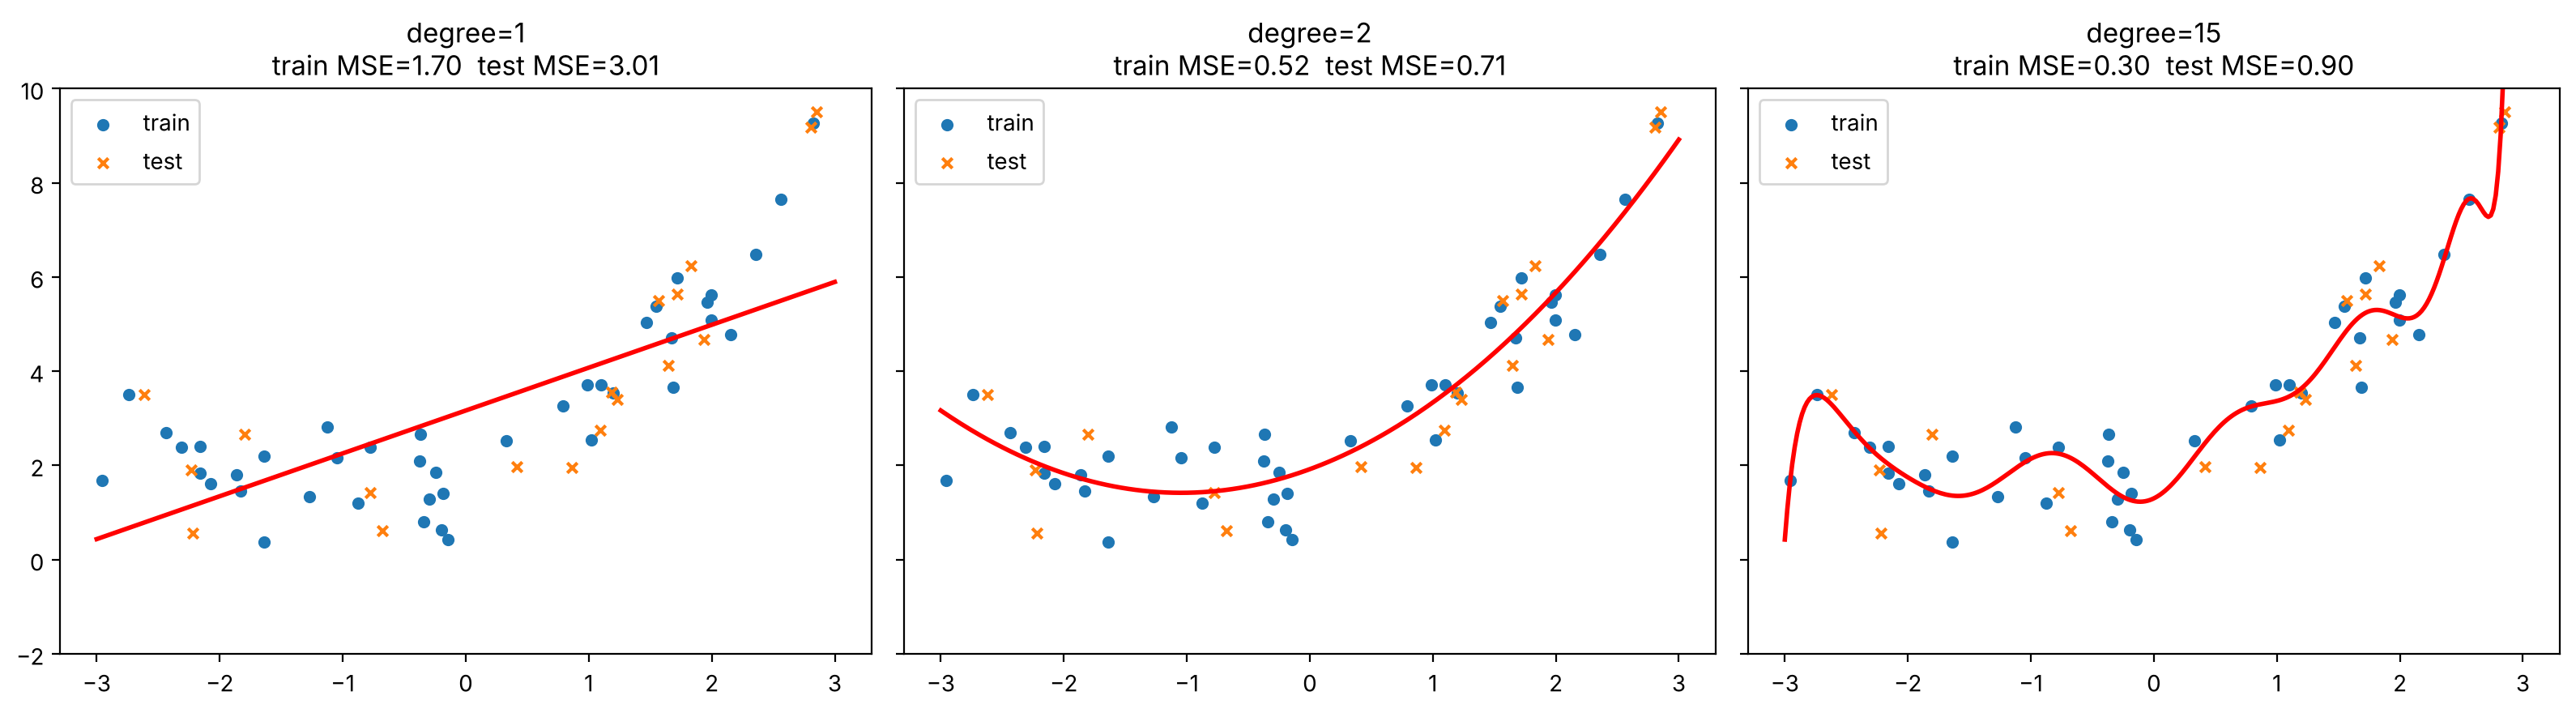

In [3]:
x_plot = np.linspace(-3, 3, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, degree in zip(axes, [1, 2, 15]):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))

    ax.scatter(X_train, y_train, s=20, label="train")
    ax.scatter(X_test, y_test, s=20, marker="x", label="test")
    ax.plot(x_plot, model.predict(x_plot), color="red", linewidth=2)
    ax.set_ylim(-2, 10)
    ax.set_title(f"degree={degree}\ntrain MSE={train_mse:.2f}  test MSE={test_mse:.2f}")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

<div dir="rtl">

- **درجه‌ی ۱ (کم‌برازش):** خط راست نمی‌تواند انحنای داده را بگیرد. خطا روی آموزش و آزمون **هر دو** زیاد است.
- **درجه‌ی ۲ (مناسب):** شکل واقعی داده را گرفته و خطای آزمون کمترین است.
- **درجه‌ی ۱۵ (بیش‌برازش):** منحنی پیچ‌وتاب می‌خورد تا از نقاط آموزشی رد شود. خطای آموزش کم است، ولی خطای آزمون زیاد است؛ مدل **نویز** را حفظ کرده، نه الگو را.

</div>

<div dir="rtl">

## ۳. مصالحه‌ی بایاس و واریانس

خطای پیش‌بینی یک مدل روی داده‌ی جدید را می‌توان به سه بخش تقسیم کرد:

</div>

$$\text{Expected error} = \text{Bias}^2 + \text{Variance} + \text{Irreducible noise}$$

<div dir="rtl">

- **بایاس (Bias):** خطای ناشی از فرض‌های ساده‌کننده‌ی مدل. مدل ساده (مثل خط برای داده‌ی منحنی) بایاس زیاد دارد و **کم‌برازش** می‌شود.
- **واریانس (Variance):** حساسیت مدل به تغییرات کوچک داده‌ی آموزش. مدل بسیار پیچیده واریانس زیاد دارد؛ اگر داده‌ی آموزش کمی عوض شود، مدل کاملاً متفاوتی به دست می‌آید. این یعنی **بیش‌برازش**.
- **نویز غیرقابل‌کاهش:** هیچ مدلی نمی‌تواند آن را حذف کند.

با پیچیده‌تر کردن مدل، بایاس کم و واریانس زیاد می‌شود. هدف، پیدا کردن نقطه‌ی تعادل است.

بیایید واریانس را مستقیم ببینیم: هر مدل را ۲۰ بار روی ۲۰ نمونه‌ی تصادفی متفاوت از داده آموزش می‌دهیم.

</div>

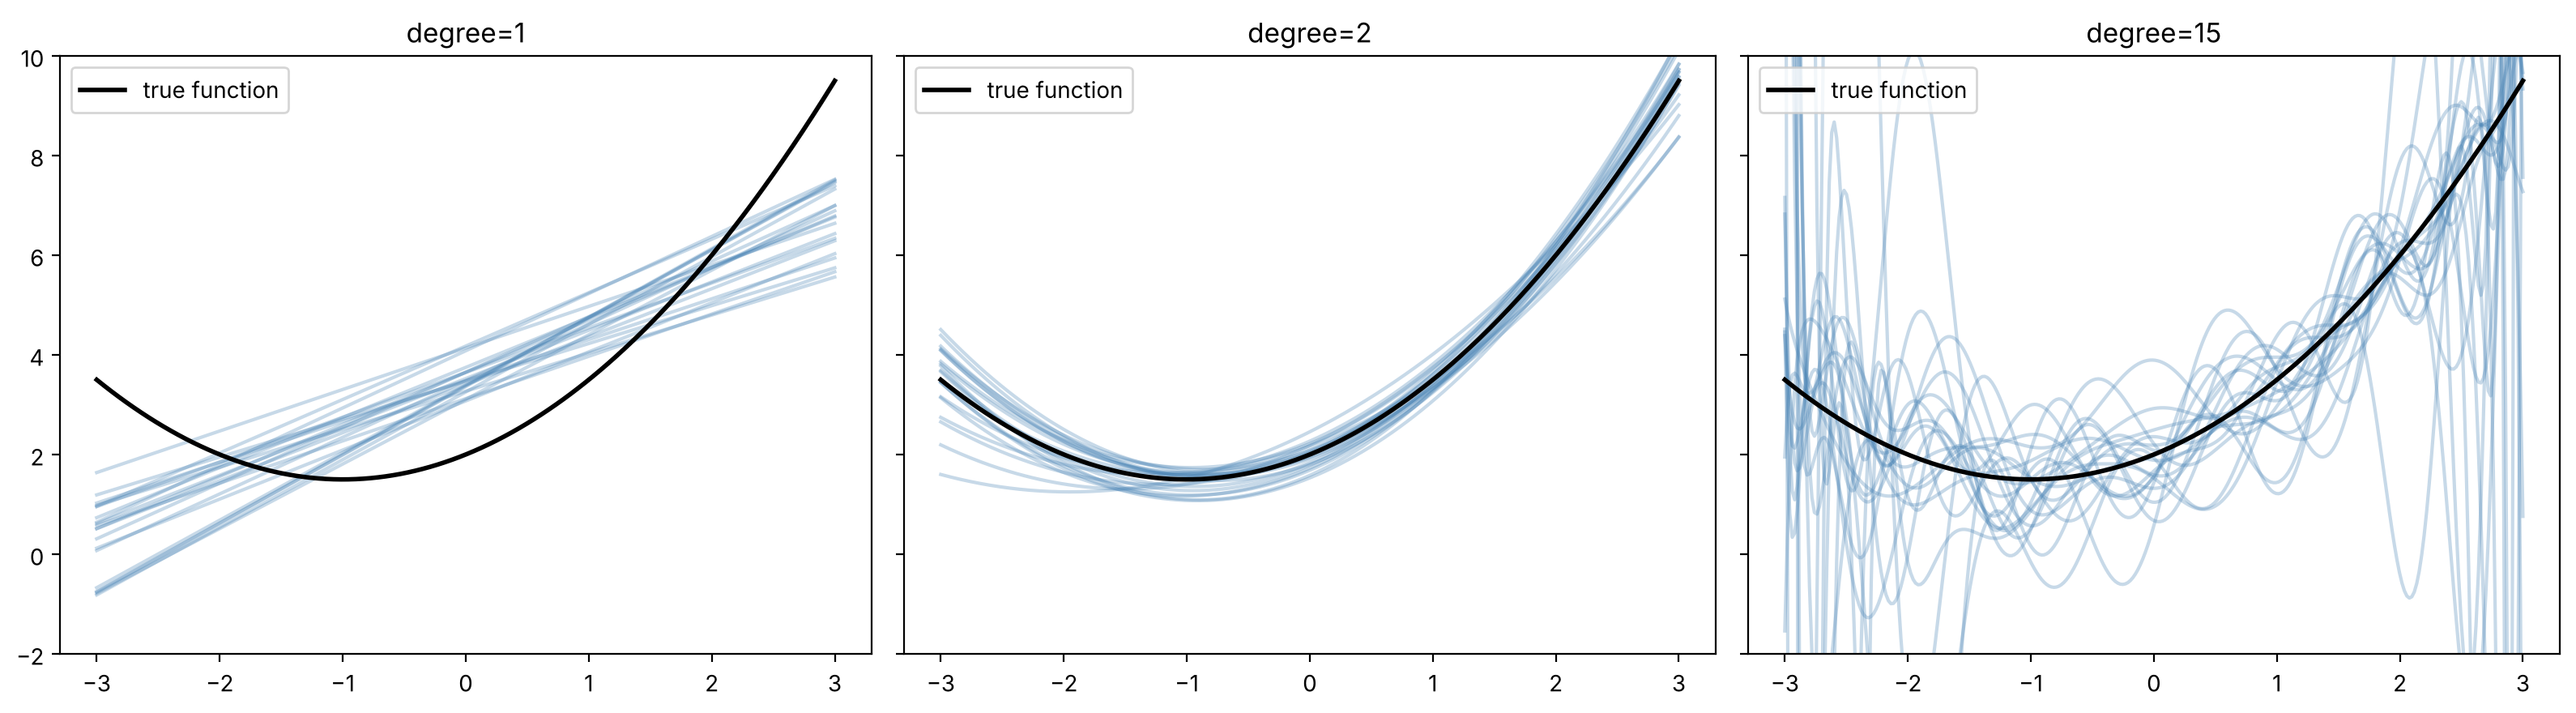

In [4]:
def true_function(x):
    return 0.5 * x ** 2 + x + 2

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, degree in zip(axes, [1, 2, 15]):
    for seed in range(20):
        r = np.random.default_rng(seed)
        Xs = 6 * r.random((30, 1)) - 3
        ys = true_function(Xs[:, 0]) + r.normal(0, 1, 30)
        model = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())
        model.fit(Xs, ys)
        ax.plot(x_plot, model.predict(x_plot), color="steelblue", alpha=0.3)
    ax.plot(x_plot, true_function(x_plot), color="black", linewidth=2, label="true function")
    ax.set_ylim(-2, 10)
    ax.set_title(f"degree={degree}")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

<div dir="rtl">

- درجه‌ی ۱: همه‌ی خط‌ها شبیه هم‌اند (واریانس کم) ولی همه از تابع واقعی دورند (بایاس زیاد).
- درجه‌ی ۲: منحنی‌ها هم به تابع واقعی نزدیک‌اند و هم به هم.
- درجه‌ی ۱۵: هر منحنی کاملاً متفاوت است (واریانس بسیار زیاد).

</div>

<div dir="rtl">

## ۴. منحنی اعتبارسنجی: انتخاب پیچیدگی مدل

در عمل تابع واقعی را نمی‌دانیم. پس چطور درجه را انتخاب کنیم؟ **نباید** از داده‌ی آزمون استفاده کنیم، چون آن داده فقط برای ارزیابی نهایی است. به‌جای آن از **اعتبارسنجی متقابل (Cross-Validation)** روی داده‌ی آموزش استفاده می‌کنیم: داده‌ی آموزش چند بار به بخش آموزش و اعتبارسنجی تقسیم می‌شود. (جزئیات در جلسه‌ی ۱۰.)

</div>

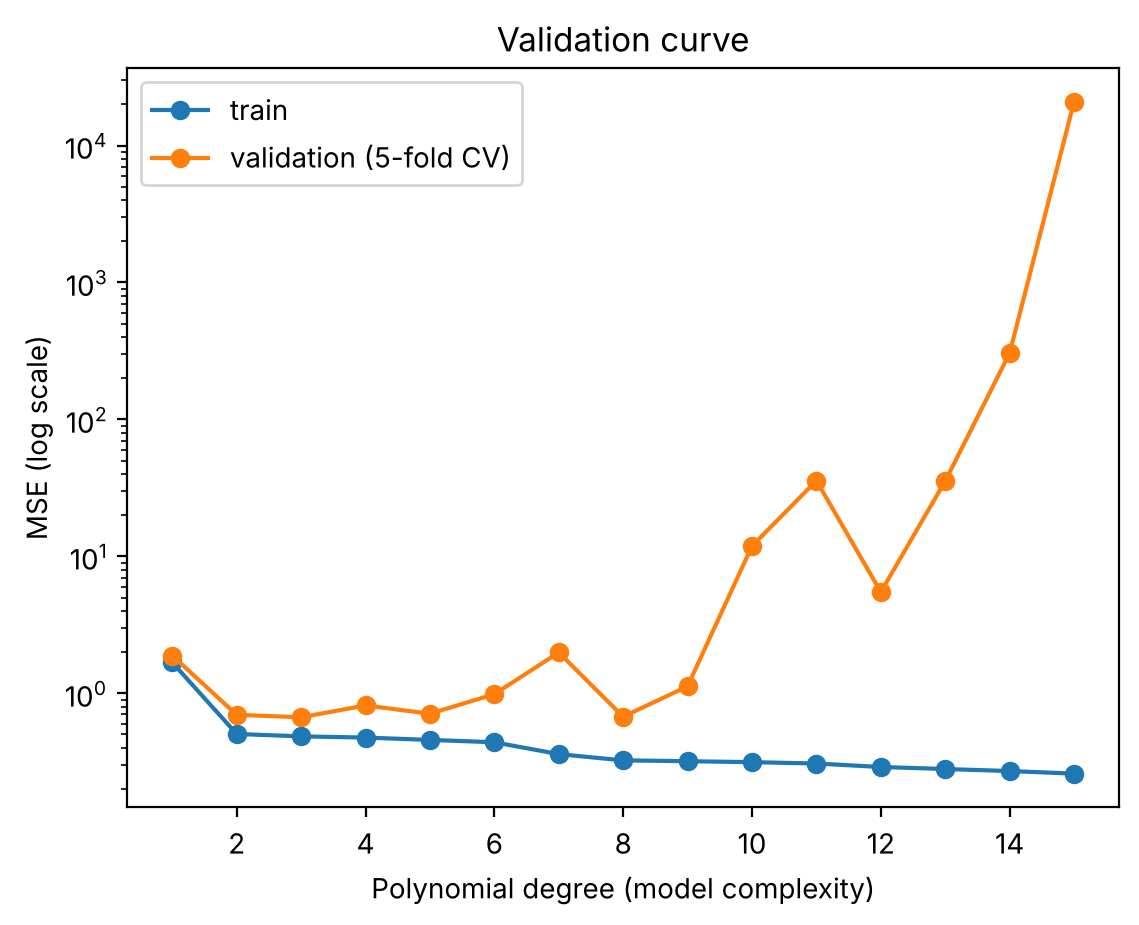

Best degree by cross-validation: 3


In [5]:
from sklearn.model_selection import validation_curve

degrees = np.arange(1, 16)
model = make_pipeline(PolynomialFeatures(include_bias=False), StandardScaler(), LinearRegression())
train_scores, val_scores = validation_curve(
    model, X_train, y_train,
    param_name="polynomialfeatures__degree", param_range=degrees,
    cv=5, scoring="neg_mean_squared_error",
)

plt.plot(degrees, -train_scores.mean(axis=1), "o-", label="train")
plt.plot(degrees, -val_scores.mean(axis=1), "o-", label="validation (5-fold CV)")
plt.yscale("log")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("MSE (log scale)")
plt.title("Validation curve")
plt.legend()
plt.show()

best_degree = degrees[np.argmax(val_scores.mean(axis=1))]
print("Best degree by cross-validation:", best_degree)

<div dir="rtl">

این نمودار شکل کلاسیک مصالحه‌ی بایاس-واریانس است: با افزایش پیچیدگی، خطای آموزش همیشه کم می‌شود، ولی خطای اعتبارسنجی ابتدا کم و بعد زیاد می‌شود. بهترین مدل در کمینه‌ی منحنی اعتبارسنجی است.

## ۵. منحنی یادگیری: آیا داده‌ی بیشتر کمک می‌کند؟

**منحنی یادگیری (Learning Curve)** خطا را بر حسب **اندازه‌ی داده‌ی آموزش** نشان می‌دهد و به ما می‌گوید مشکل مدل بایاس است یا واریانس.

</div>

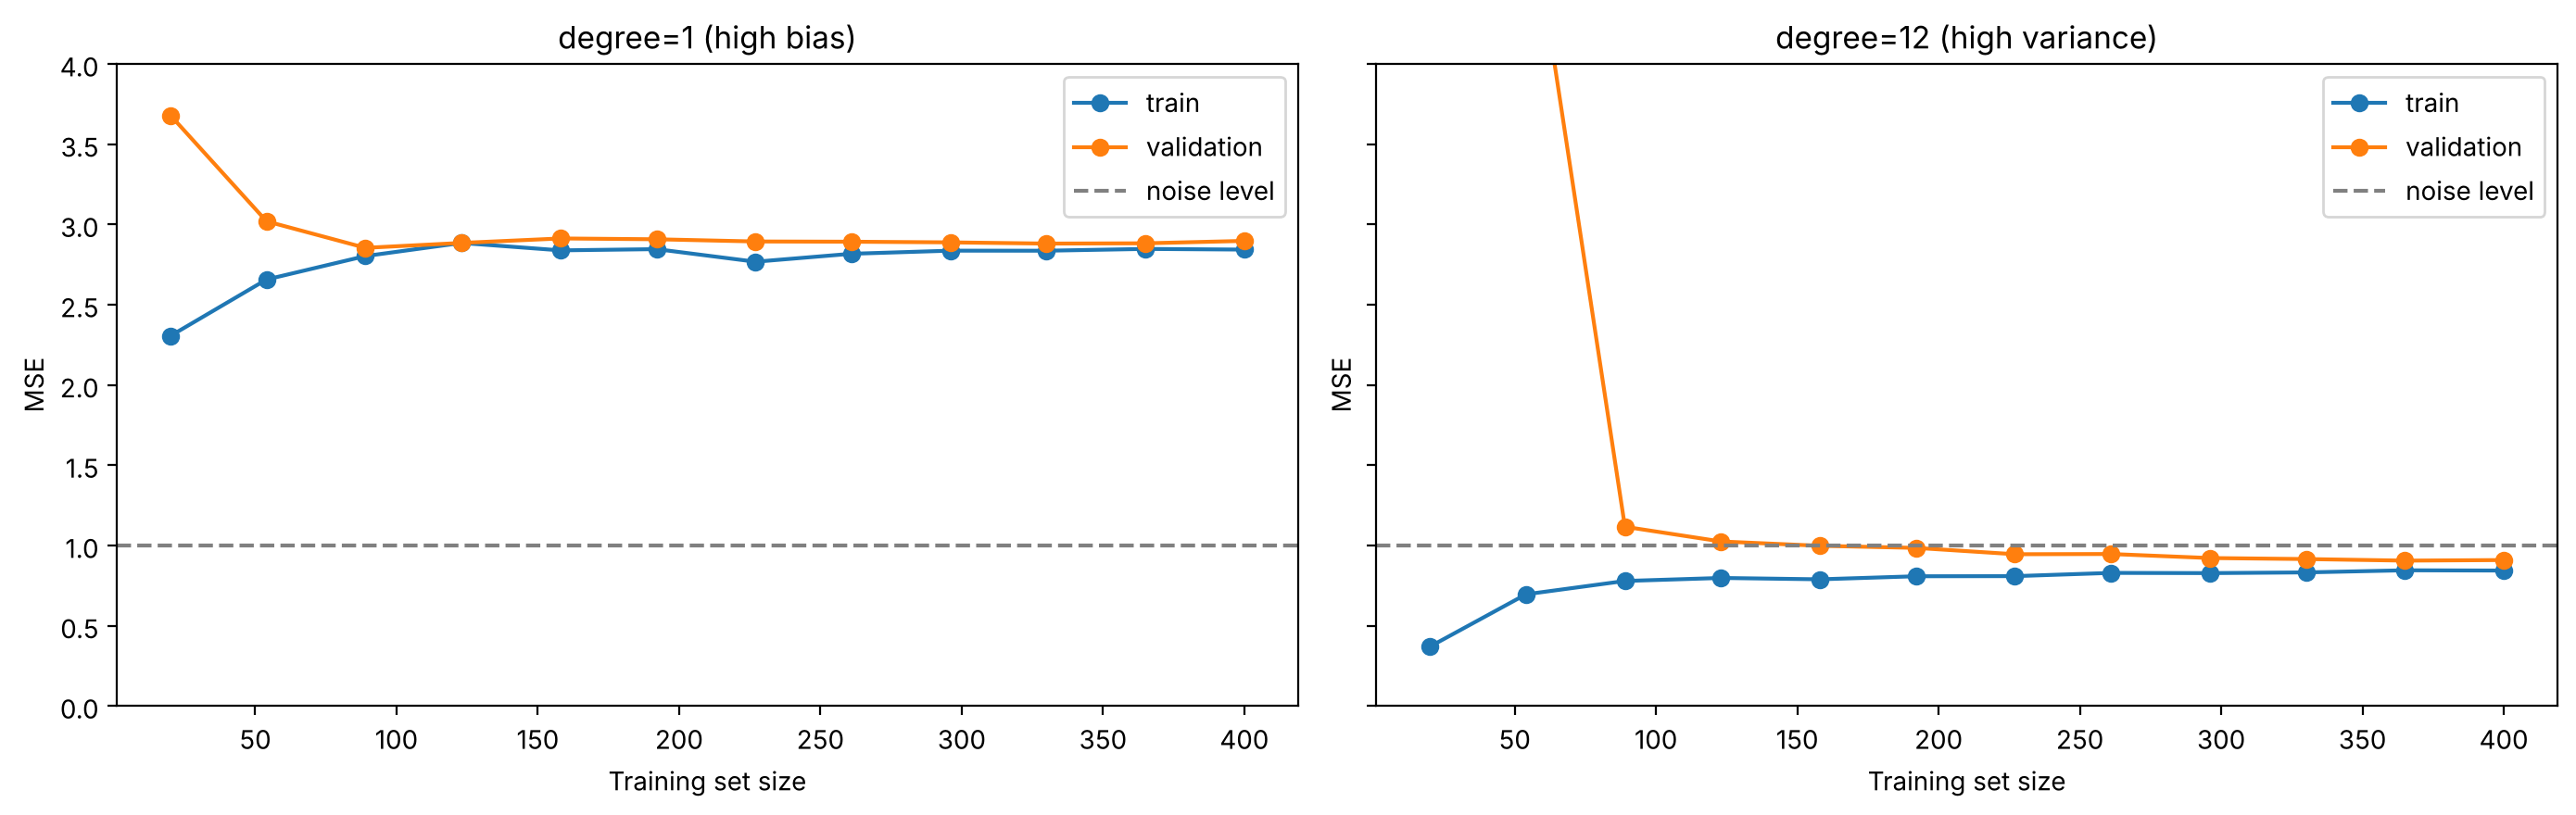

In [6]:
from sklearn.model_selection import learning_curve

rng = np.random.default_rng(0)
X_big = 6 * rng.random((500, 1)) - 3
y_big = true_function(X_big[:, 0]) + rng.normal(0, 1, 500)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, degree, title in zip(axes, [1, 12], ["degree=1 (high bias)", "degree=12 (high variance)"]):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())
    sizes, tr, va = learning_curve(model, X_big, y_big, cv=5, scoring="neg_mean_squared_error",
                                   train_sizes=np.linspace(0.05, 1.0, 12), shuffle=True, random_state=0)
    ax.plot(sizes, -tr.mean(axis=1), "o-", label="train")
    ax.plot(sizes, -va.mean(axis=1), "o-", label="validation")
    ax.axhline(1.0, color="gray", linestyle="--", label="noise level")
    ax.set_ylim(0, 4)
    ax.set_xlabel("Training set size")
    ax.set_ylabel("MSE")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl">

**تفسیر:**
- **بایاس زیاد (چپ):** دو منحنی خیلی زود به هم می‌رسند و در سطح بالایی ثابت می‌مانند. **داده‌ی بیشتر کمکی نمی‌کند**؛ باید مدل پیچیده‌تر یا ویژگی‌های بهتری استفاده کرد.
- **واریانس زیاد (راست):** با داده‌ی کم، فاصله‌ی زیادی بین خطای آموزش و اعتبارسنجی وجود دارد، ولی با افزایش داده این فاصله کم می‌شود. **داده‌ی بیشتر کمک می‌کند**؛ راه دیگر، ساده‌تر کردن مدل یا **منظم‌سازی** است.

| مشکل | نشانه | راه حل |
|---|---|---|
| کم‌برازش (بایاس زیاد) | خطای آموزش و اعتبارسنجی هر دو زیاد | مدل پیچیده‌تر، ویژگی بیشتر، منظم‌سازی کمتر |
| بیش‌برازش (واریانس زیاد) | خطای آموزش کم، خطای اعتبارسنجی زیاد | داده‌ی بیشتر، مدل ساده‌تر، **منظم‌سازی بیشتر** |

</div>

<div dir="rtl">

## ۶. منظم‌سازی (Regularization)

ایده‌ی منظم‌سازی: به تابع هزینه یک **جریمه** برای بزرگ بودن ضرایب اضافه کنیم. مدل‌های بیش‌برازش‌شده معمولاً ضرایب بسیار بزرگی دارند (همان پیچ‌وتاب‌های شدید منحنی درجه‌ی ۱۵). با محدود کردن ضرایب، مدل نرم‌تر و ساده‌تر می‌شود.

### ۶.۱ رگرسیون Ridge (منظم‌سازی L2)

</div>

$$J(\mathbf{w}) = \text{MSE}(\mathbf{w}) + \alpha \sum_{j=1}^{n} w_j^2$$

<div dir="rtl">

### ۶.۲ رگرسیون Lasso (منظم‌سازی L1)

</div>

$$J(\mathbf{w}) = \text{MSE}(\mathbf{w}) + \alpha \sum_{j=1}^{n} |w_j|$$

<div dir="rtl">

### ۶.۳ Elastic Net (ترکیب هر دو)

</div>

$$J(\mathbf{w}) = \text{MSE}(\mathbf{w}) + \alpha \left( r \sum_{j=1}^{n} |w_j| + \frac{1-r}{2} \sum_{j=1}^{n} w_j^2 \right)$$

<div dir="rtl">

- $\alpha$ قدرت منظم‌سازی را تعیین می‌کند. $\alpha = 0$ همان رگرسیون خطی معمولی است و $\alpha$ خیلی بزرگ همه‌ی ضرایب را به صفر نزدیک می‌کند.
- بایاس $b$ جریمه نمی‌شود.
- **Ridge** ضرایب را کوچک می‌کند ولی تقریباً هیچ‌وقت دقیقاً صفر نمی‌کند.
- **Lasso** بسیاری از ضرایب را **دقیقاً صفر** می‌کند؛ یعنی خودش **انتخاب ویژگی** انجام می‌دهد.
- **منظم‌سازی به مقیاس ویژگی‌ها حساس است**؛ همیشه قبل از آن استانداردسازی کنید.

حالا اثر Ridge را روی همان مدل درجه‌ی ۱۵ ببینیم:

</div>

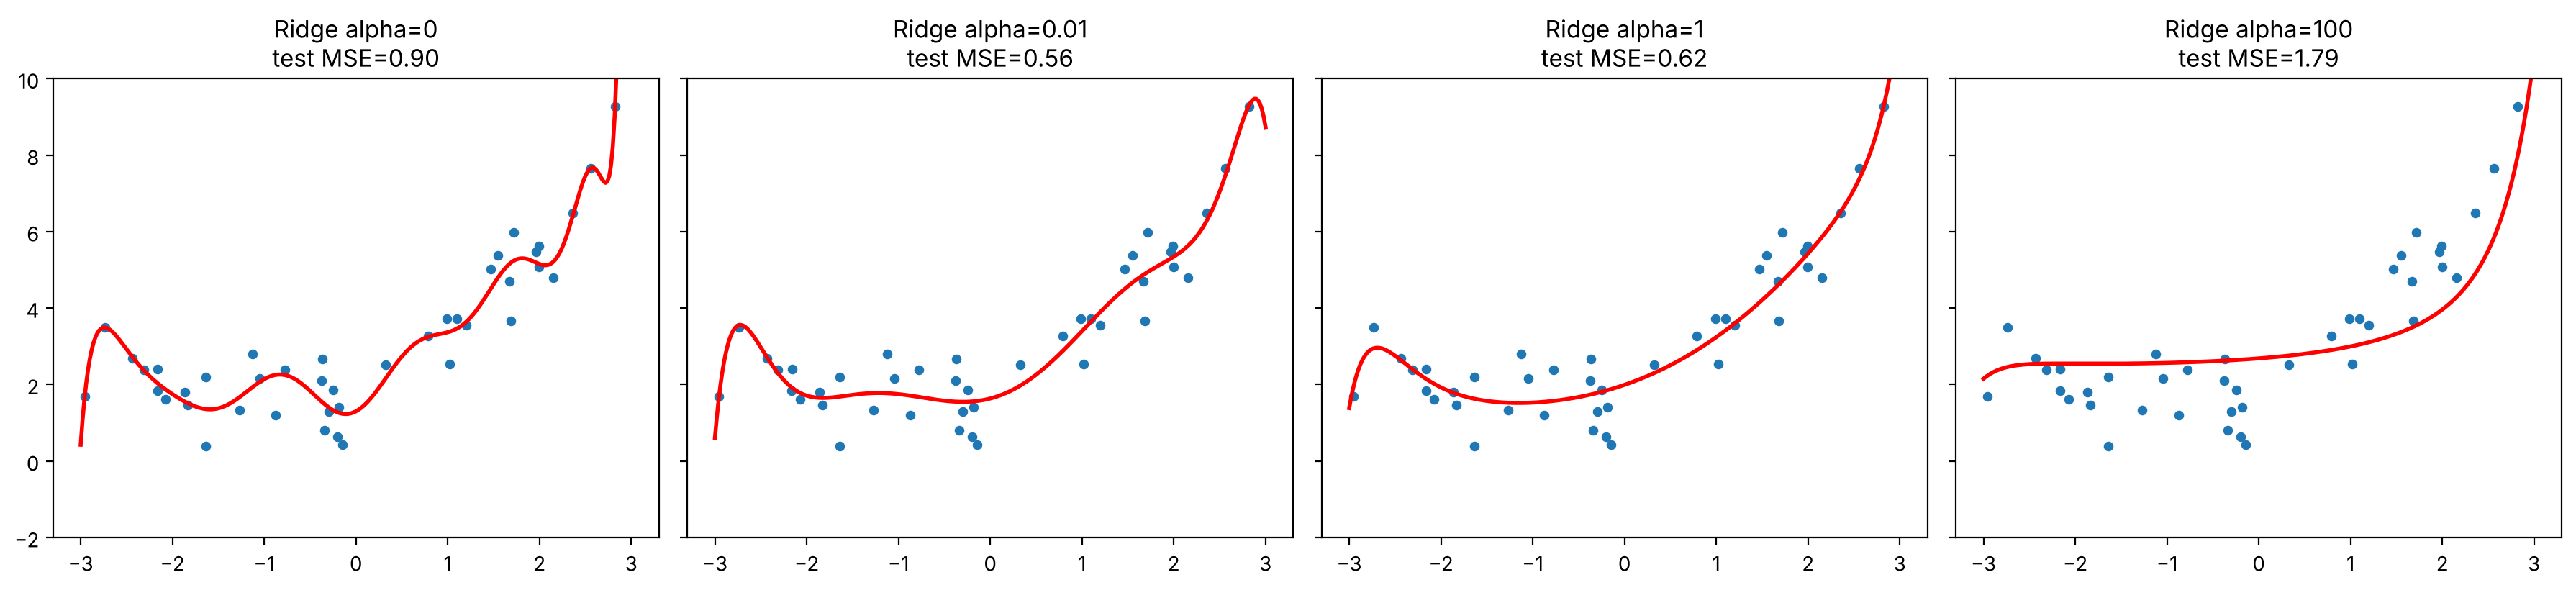

In [7]:
from sklearn.linear_model import Ridge, Lasso

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, alpha in zip(axes, [0, 0.01, 1, 100]):
    reg = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
    model = make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), reg)
    model.fit(X_train, y_train)
    test_mse = mean_squared_error(y_test, model.predict(X_test))
    ax.scatter(X_train, y_train, s=15)
    ax.plot(x_plot, model.predict(x_plot), color="red", linewidth=2)
    ax.set_ylim(-2, 10)
    ax.set_title(f"Ridge alpha={alpha}\ntest MSE={test_mse:.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

با افزایش $\alpha$، منحنی نرم‌تر می‌شود. $\alpha$ مناسب بیش‌برازش را از بین می‌برد و $\alpha$ بیش از حد بزرگ مدل را دوباره به سمت کم‌برازش می‌برد. پس $\alpha$ هم یک ابرپارامتر است که باید با اعتبارسنجی انتخاب شود.

</div>

<div dir="rtl">

## ۷. Ridge و Lasso روی داده‌ی واقعی: داده‌ی دیابت

مجموعه‌داده‌ی دیابت scikit-learn شامل ۱۰ ویژگی بالینی (سن، جنسیت، شاخص توده‌ی بدنی، فشار خون و شش اندازه‌گیری خونی) از ۴۴۲ بیمار است. هدف، شاخصی از پیشرفت بیماری یک سال بعد است. ویژگی‌ها از قبل مقیاس‌بندی شده‌اند.

</div>

In [8]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)
X_d, y_d = diabetes.data, diabetes.target
X_d.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


<div dir="rtl">

### ۷.۱ مسیر ضرایب (Coefficient Path)

ضرایب هر مدل را به‌ازای مقادیر مختلف $\alpha$ رسم می‌کنیم:

</div>

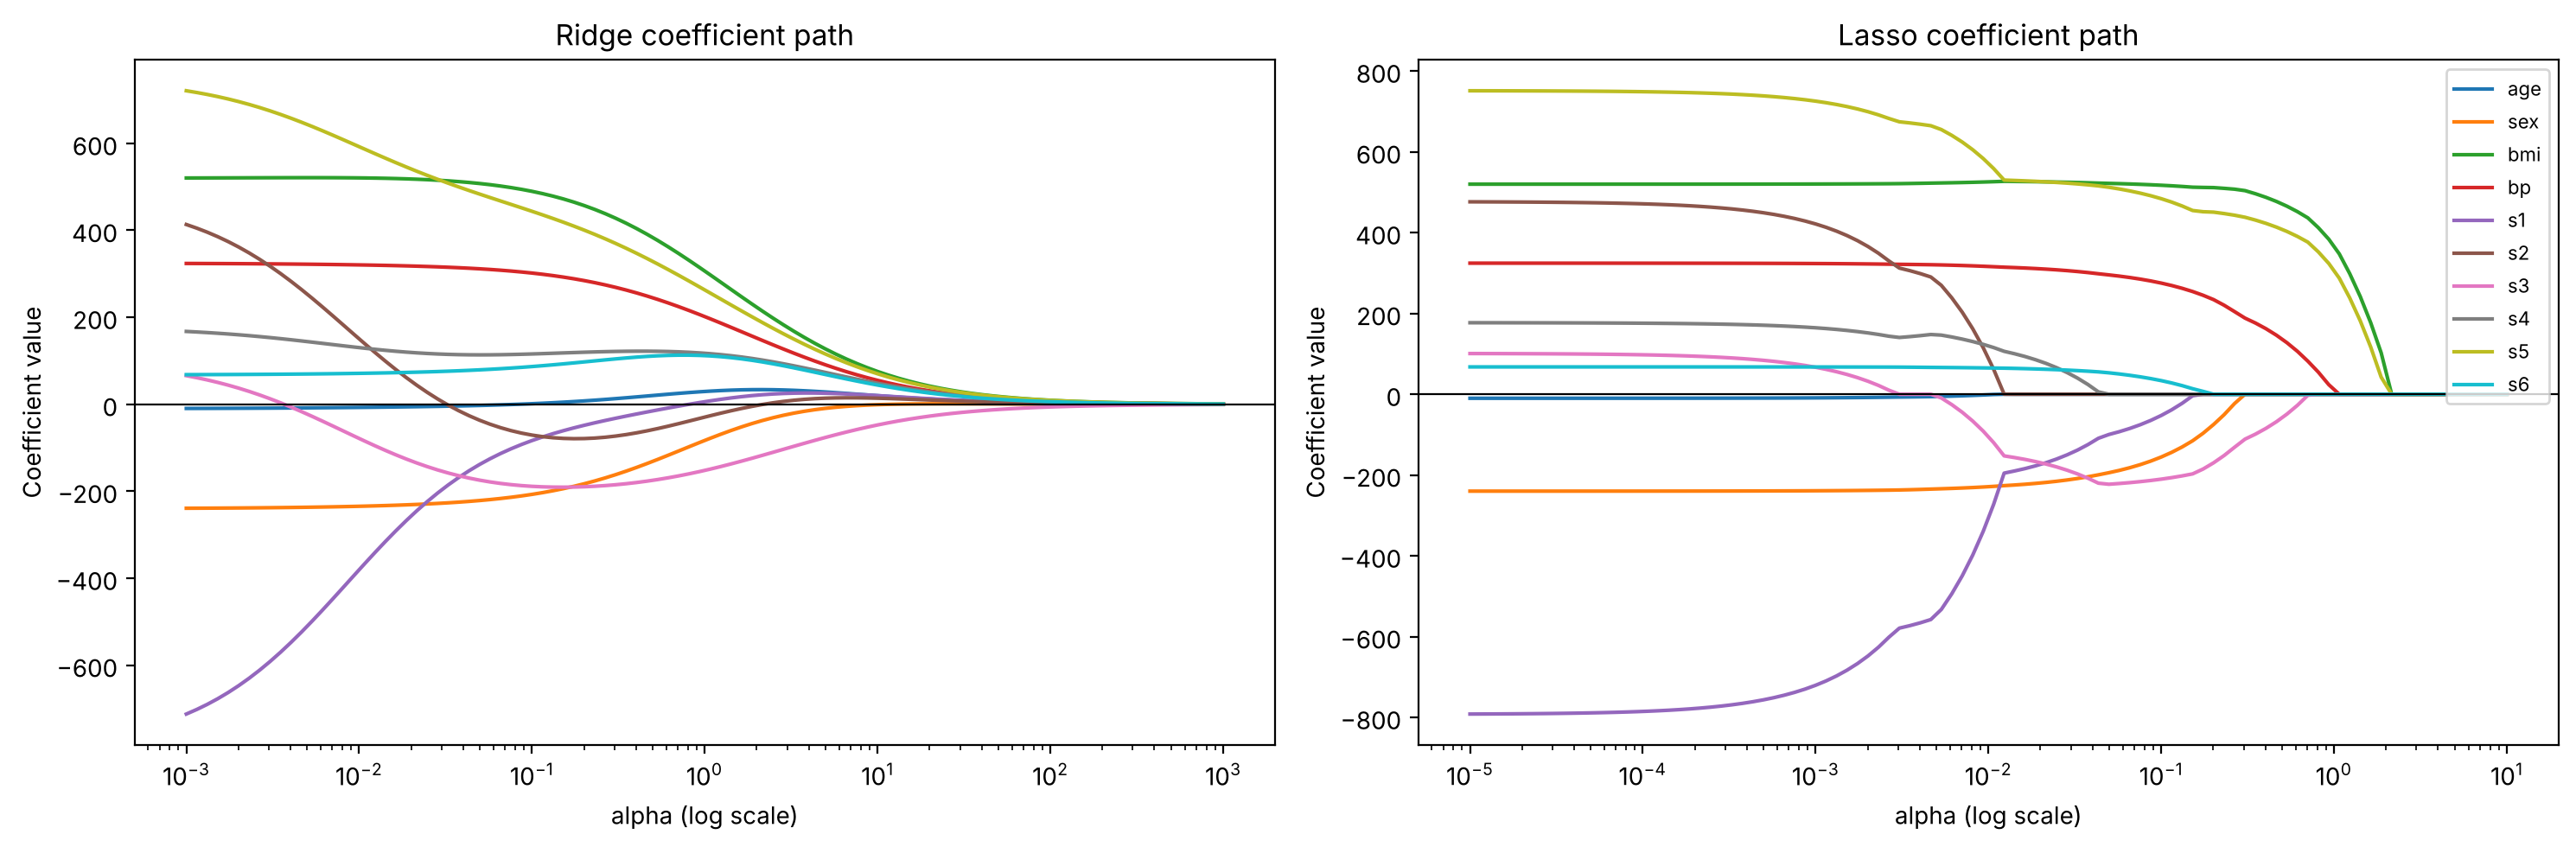

In [9]:
alphas = np.logspace(-3, 3, 100)
ridge_coefs = [Ridge(alpha=a).fit(X_d, y_d).coef_ for a in alphas]
lasso_coefs = [Lasso(alpha=a / 100, max_iter=10_000).fit(X_d, y_d).coef_ for a in alphas]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, coefs, title, xs in [(axes[0], ridge_coefs, "Ridge", alphas),
                             (axes[1], lasso_coefs, "Lasso", alphas / 100)]:
    ax.plot(xs, coefs)
    ax.set_xscale("log")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("Coefficient value")
    ax.set_title(f"{title} coefficient path")
axes[1].legend(X_d.columns, loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

<div dir="rtl">

- در **Ridge** همه‌ی ضرایب به‌آرامی و با هم به سمت صفر می‌روند.
- در **Lasso** ضرایب یکی‌یکی **دقیقاً صفر** می‌شوند. ویژگی‌هایی که تا $\alpha$ بزرگ باقی می‌مانند (مثل `bmi` و `s5`)، مهم‌ترین ویژگی‌ها هستند.

### ۷.۲ انتخاب $\alpha$ با اعتبارسنجی متقابل

کلاس‌های `RidgeCV` و `LassoCV` بهترین $\alpha$ را خودشان با اعتبارسنجی متقابل پیدا می‌کنند:

</div>

In [10]:
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.model_selection import cross_val_score

X_tr, X_te, y_tr, y_te = train_test_split(X_d, y_d, test_size=0.25, random_state=42)

models = {
    "Linear regression": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=np.logspace(-3, 3, 50)),
    "LassoCV": LassoCV(alphas=np.logspace(-3, 1, 50), cv=5, max_iter=10_000),
}
rows = []
for name, model in models.items():
    model.fit(X_tr, y_tr)
    rows.append({
        "model": name,
        "alpha": getattr(model, "alpha_", 0),
        "test RMSE": np.sqrt(mean_squared_error(y_te, model.predict(X_te))),
        "nonzero coefs": int(np.sum(np.abs(model.coef_) > 1e-8)),
    })
pd.DataFrame(rows).round(3)

,model,alpha,test RMSE,nonzero coefs
0,Linear regression,0.000,53.370,10
1,RidgeCV,0.003,53.308,10
2,LassoCV,0.005,53.271,9


In [11]:
lasso = models["LassoCV"]
pd.Series(lasso.coef_, index=X_d.columns).round(2).sort_values()

s1    -653.08
sex   -236.72
s3      -0.00
s6      27.05
age     46.68
s4     229.00
s2     302.37
bp     377.61
bmi    536.97
s5     596.99
dtype: float64

<div dir="rtl">

در این داده، چون تعداد ویژگی‌ها کم و تعداد نمونه‌ها نسبتاً زیاد است، بیش‌برازش شدید نداریم و منظم‌سازی تفاوت بزرگی در خطا ایجاد نمی‌کند. ولی Lasso با صفر کردن ضریب `s3`، مدل ساده‌تری با دقت مشابه ساخته است. با $\alpha$ بزرگ‌تر، ویژگی‌های بیشتری حذف می‌شوند و مدل ساده‌تر و تفسیرپذیرتر می‌شود. منظم‌سازی وقتی بیشترین اثر را دارد که تعداد ویژگی‌ها نسبت به نمونه‌ها زیاد باشد؛ مثل ویژگی‌های چندجمله‌ای که الان می‌سازیم:

</div>

In [12]:
for name, reg in [("Polynomial (degree 3), no regularization", LinearRegression()),
                  ("Polynomial (degree 3) + RidgeCV", RidgeCV(alphas=np.logspace(-2, 4, 50)))]:
    model = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), reg)
    scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring="neg_root_mean_squared_error")
    n_features = PolynomialFeatures(3, include_bias=False).fit(X_tr).n_output_features_
    print(f"{name:<45} features={n_features}  CV RMSE={-scores.mean():.1f}")

Polynomial (degree 3), no regularization      features=285  CV RMSE=5331.4
Polynomial (degree 3) + RidgeCV               features=285  CV RMSE=60.5


<div dir="rtl">

با ۲۸۵ ویژگی چندجمله‌ای و فقط حدود ۳۳۰ نمونه‌ی آموزشی، رگرسیون خطی بدون منظم‌سازی به‌شدت بیش‌برازش می‌کند و خطایش ده‌ها برابر می‌شود. Ridge همین مدل را کاملاً قابل استفاده می‌کند.

## ۸. جمع‌بندی

- رگرسیون چندجمله‌ای با ساختن ویژگی‌های توانی، رابطه‌های غیرخطی را مدل می‌کند.
- مدل ساده بایاس زیاد دارد (کم‌برازش) و مدل پیچیده واریانس زیاد (بیش‌برازش).
- پیچیدگی مدل را با **منحنی اعتبارسنجی** انتخاب کنید و با **منحنی یادگیری** بفهمید داده‌ی بیشتر کمک می‌کند یا نه.
- منظم‌سازی با جریمه‌ی ضرایب بزرگ، بیش‌برازش را کنترل می‌کند: Ridge ضرایب را کوچک و Lasso بعضی را صفر می‌کند.
- ضریب $\alpha$ یک ابرپارامتر است و باید با اعتبارسنجی متقابل انتخاب شود، نه با داده‌ی آزمون.

## ۹. تمرین

1. منحنی اعتبارسنجی بخش ۴ را با `Ridge(alpha=1)` به‌جای `LinearRegression` دوباره رسم کنید. شکل منحنی برای درجه‌های بالا چطور تغییر می‌کند؟
2. منحنی یادگیری را برای مدل درجه‌ی ۲ رسم کنید و با دو منحنی بخش ۵ مقایسه کنید.
3. روی داده‌ی مسکن جلسه‌ی ۳، Pipeline با `PolynomialFeatures(degree=2)` و `RidgeCV` بسازید. RMSE آزمون نسبت به رگرسیون خطی ساده بهتر می‌شود؟
4. `ElasticNetCV` را روی داده‌ی دیابت امتحان کنید و `l1_ratio` بهینه را گزارش کنید.

</div>